# 統計的機械翻訳の基礎（IBM Model 1・フレーズベース SMT）・BLEU 評価・翻訳メモリ・対訳フィルタリング

書籍 第4章「言語生成問題の解き方」（4-2-1 ルールベース・図 4.6、4-2-2 統計ベース・図 4.7〜4.9・関連論文 4章 7、4-2-4 評価・図 4.11、4-2-5 コーパス）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、翻訳支援から対訳データ品質管理・単語アライメント対称化・フレーズベース SMT デコーディング・自動評価までを一貫して体験します。

1. **IBM Model 1（EM アルゴリズム）による単語アライメントと対訳確率の学習**（4-2-2、p.139〜142）
2. **翻訳モデル × 言語モデル（ノイジーチャネルモデル）による語順選択の考え方**（4-2-2、p.141）
3. **BLEU の定義式実装（クリッピング・簡潔性ペナルティ）と `sacrebleu` との一致確認**（4-2-4、p.153）
4. **図 4.11（p.154）の再現**：シングルリファレンス vs マルチリファレンス BLEU-2、および文単位 BLEU（脚注 43）
5. **表層一致に基づく評価尺度の限界**（言い換え・語順・否定反転）
6. **翻訳メモリ (Translation Memory) によるあいまい一致検索と訳語統一**（4-2-1・図 4.6、p.146〜147）
7. **コンパラブルコーパス・Web 対訳からの文アライメント信頼度とノイズフィルタリング**（4-2-5、p.157〜158）
8. **双方向単語アライメントの対称化とフレーズ抽出・フレーズベース SMT デコーディング**（4-2-2・図 4.7〜4.9・関連論文 4章 7）

In [1]:
!pip install -q sacrebleu

ERROR: Could not find an activated virtualenv (required).


In [2]:
import math
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu

---

## 1. IBM Model 1（EM アルゴリズム）による単語アライメント獲得（4-2-2）

統計的機械翻訳では、対訳コーパスから**どの原言語単語がどの目的言語単語に対応するか（単語アライメント）**を教師なしで推定する **IBM Model 1** が基礎となります。
わずかな英日対訳文ペアに対して EM アルゴリズムを数回反復するだけで、対訳確率 $t(f \mid e)$ が自然に収束する様子を確認しましょう。

In [3]:
parallel_corpus = [
    (["i", "like", "cats"], ["私", "は", "猫", "が", "好き"]),
    (["i", "like", "dogs"], ["私", "は", "犬", "が", "好き"]),
    (["she", "likes", "music"], ["彼女", "は", "音楽", "が", "好き"]),
    (["he", "likes", "books"], ["彼", "は", "本", "が", "好き"]),
    (["i", "read", "books"], ["私", "は", "本", "を", "読む"]),
    (["i", "read", "a", "book"], ["私", "は", "本", "を", "読む"]),
    (["she", "reads", "a", "book"], ["彼女", "は", "本", "を", "読む"]),
    (["he", "writes", "a", "book"], ["彼", "は", "本", "を", "書く"]),
    (["big", "book"], ["大きな", "本"]),
    (["small", "book"], ["小さな", "本"]),
    (["big", "cats", "run"], ["大きな", "猫", "が", "走る"]),
    (["big", "dogs", "run"], ["大きな", "犬", "が", "走る"]),
    (["small", "cats", "sleep"], ["小さな", "猫", "が", "眠る"]),
    (["small", "dogs", "sleep"], ["小さな", "犬", "が", "眠る"]),
    (["dogs", "sleep"], ["犬", "が", "眠る"]),
    (["i", "see", "big", "cats"], ["私", "は", "大きな", "猫", "を", "見る"]),
]

def train_ibm_model1(pairs, n_iter=20):
    en_vocab = {"<NULL>"} | {w for en, _ in pairs for w in en}
    ja_vocab = {w for _, ja in pairs for w in ja}
    # 初期値は一様分布
    t = defaultdict(lambda: 1.0 / len(ja_vocab))

    for _ in range(n_iter):
        count = defaultdict(float)
        total = defaultdict(float)
        for en, ja in pairs:
            en_with_null = ["<NULL>"] + en
            for f in ja:
                z = sum(t[(f, e)] for e in en_with_null)
                for e in en_with_null:
                    c = t[(f, e)] / z
                    count[(f, e)] += c
                    total[e] += c
        for (f, e), val in count.items():
            t[(f, e)] = val / total[e]
    return t

t_prob = train_ibm_model1(parallel_corpus, n_iter=20)

# 主な英単語に対して学習された上位の日本語訳確率を表示
sample_words = ["cats", "dogs", "book", "books", "read", "writes", "big", "small", "run", "sleep"]
rows = []
for ew in sample_words:
    cands = sorted(
        ((jw, p) for (jw, e), p in t_prob.items() if e == ew),
        key=lambda x: x[1],
        reverse=True,
    )[:2]
    rows.append({
        "英単語 e": ew,
        "最有力訳語 f1": f"{cands[0][0]} ({cands[0][1]:.2f})",
        "次点訳語 f2": f"{cands[1][0]} ({cands[1][1]:.2f})" if len(cands) > 1 else "-",
    })
display(pd.DataFrame(rows))

,英単語 e,最有力訳語 f1,次点訳語 f2
0,cats,猫 (0.96),が (0.04)
1,dogs,犬 (0.86),が (0.14)
2,book,本 (1.00),を (0.00)
3,books,本 (0.81),は (0.16)
4,read,読む (0.61),を (0.38)
5,writes,書く (0.83),を (0.11)
6,big,大きな (1.00),走る (0.00)
7,small,小さな (1.00),眠る (0.00)
8,run,走る (0.83),が (0.16)
9,sleep,眠る (0.84),が (0.16)


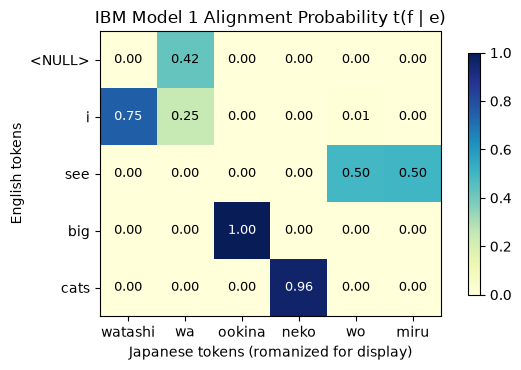

In [4]:
# 1文についてアライメント確率行列 t(f|e) をヒートマップで可視化
en_sent = ["<NULL>", "i", "see", "big", "cats"]
ja_sent = ["私", "は", "大きな", "猫", "を", "見る"]
mat = np.array([[t_prob[(f, e)] for f in ja_sent] for e in en_sent])

fig, ax = plt.subplots(figsize=(6.2, 3.8))
im = ax.imshow(mat, cmap="YlGnBu", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(ja_sent)), labels=["watashi", "wa", "ookina", "neko", "wo", "miru"])
ax.set_yticks(range(len(en_sent)), labels=en_sent)
ax.set_xlabel("Japanese tokens (romanized for display)")
ax.set_ylabel("English tokens")
ax.set_title("IBM Model 1 Alignment Probability t(f | e)")
for i in range(len(en_sent)):
    for j in range(len(ja_sent)):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                color="white" if mat[i, j] > 0.55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

英語の語順（S V O：`i see big cats`）と日本語の語順（S O V：`私 は 大きな 猫 を 見る`）が交差していても、`see → 見る`、`big → 大きな`、`cats → 猫` の対応を統計的に見つけられています。表に示す $t(f \mid e)$ は語彙翻訳確率です。個々の文でどの位置が対応するかを表すアライメントの事後確率とは区別します。

さらに書籍 4-2-2（p.141）の式：

$$\hat{e} = \arg\max_e P(e \mid f) = \arg\max_e P(f \mid e) P(e)$$

のとおり、**翻訳モデル $P(f \mid e)$（単語対応の良さ）** だけでは語順がバラバラになりがちですが、**言語モデル $P(e)$（流暢さ）** を掛け合わせることで自然な語順の候補を選べます。

---

## 2. BLEU の定義式実装と検証（4-2-4、p.153）

機械翻訳の自動評価で広く使われる **BLEU** は、次の 2 要素の積で定義されます（書籍 p.153、$N$ は通常 4）。

$$\mathrm{BLEU} = \mathrm{BP} \times \exp\left(\sum_{n=1}^{N} w_n \log(p_n)\right), \quad \mathrm{BP} = \begin{cases} 1 & (c > r) \\ \exp(1 - r/c) & (c \le r) \end{cases}$$

（※ 書籍第 1 刷 p.153 では指数関数の中身が誤って逆数 `1 / ...` として記載されています（[正誤表](https://github.com/mamorlis/nlpbook/blob/main/errata.md)）。本ノートブックでは正しい定義式を実装し、`sacrebleu` と一致することを確認します。）

In [5]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def compute_bleu(hypotheses, references_list, max_n=4):
    """コーパスレベル BLEU（複数リファレンス対応、smooth_method='none' 相当）"""
    clipped_counts = [0] * max_n
    total_counts = [0] * max_n
    hyp_len = 0
    ref_len = 0

    for idx, hyp in enumerate(hypotheses):
        h_tok = hyp.split()
        hyp_len += len(h_tok)
        refs_tok = [refs[idx].split() for refs in references_list]
        # 出力長に最も近い参照訳長を代表値 r とする
        ref_len += min((len(rt) for rt in refs_tok), key=lambda l: (abs(l - len(h_tok)), l))

        for n in range(1, max_n + 1):
            h_ng = Counter(ngrams(h_tok, n))
            max_r_ng = Counter()
            for rt in refs_tok:
                r_ng = Counter(ngrams(rt, n))
                for ng, cnt in r_ng.items():
                    if cnt > max_r_ng[ng]:
                        max_r_ng[ng] = cnt
            clipped_counts[n - 1] += sum(min(cnt, max_r_ng[ng]) for ng, cnt in h_ng.items())
            total_counts[n - 1] += sum(h_ng.values())

    precisions = [c / t if t > 0 else 0.0 for c, t in zip(clipped_counts, total_counts)]
    bp = 1.0 if hyp_len > ref_len else math.exp(1.0 - ref_len / hyp_len)
    if min(precisions) == 0.0:
        bleu = 0.0
    else:
        bleu = bp * math.exp(sum(math.log(p) for p in precisions) / max_n)
    return bleu * 100.0, [p * 100.0 for p in precisions], bp

refs = [
    "the cat is on the mat",
    "there is a cat on the mat",
]
hyps = [
    "the cat is on the mat",
    "there is a dog on the mat",
]

my_bleu, precs, bp = compute_bleu(hyps, [refs], max_n=4)
lib_bleu = sacrebleu.corpus_bleu(hyps, [refs], tokenize="none", smooth_method="none")
print(f"手計算 BLEU   = {my_bleu:.4f} (n-gram 適合率={[round(p, 2) for p in precs]}, BP={bp:.4f})")
print(f"sacrebleu     = {lib_bleu.score:.4f}")

手計算 BLEU   = 68.1561 (n-gram 適合率=[92.31, 81.82, 66.67, 42.86], BP=1.0000)
sacrebleu     = 68.1561


### クリッピングと簡潔性ペナルティの働きを確認する

In [6]:
ref_sample = ["the cat is on the mat"]
cases = [
    ("適切な翻訳（完全一致）", ["the cat is on the mat"]),
    ("同じ語を連呼（クリッピングの検証）", ["the the the the the the"]),
    ("極端に短い出力（BP の検証）", ["the cat"]),
]

for label, h in cases:
    b_none = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="none")
    b_exp = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="exp")
    print(f"{label:32s} | BLEU(none)={b_none.score:6.2f}, BLEU(smooth)={b_exp.score:6.2f}, BP={b_none.bp:.3f}, p1={b_none.precisions[0]:.1f}")

適切な翻訳（完全一致）                      | BLEU(none)=100.00, BLEU(smooth)=100.00, BP=1.000, p1=100.0
同じ語を連呼（クリッピングの検証）                | BLEU(none)=  0.00, BLEU(smooth)=  9.65, BP=1.000, p1=33.3
極端に短い出力（BP の検証）                  | BLEU(none)=  0.00, BLEU(smooth)=  0.00, BP=0.135, p1=100.0


- `"the the the the the the"` は 6 単語すべてが参照文の `"the"` と一致するため、クリッピングなしでは 1-gram 適合率が 100% になってしまいますが、クリッピングにより参照文中の出現回数（2回）までに制限され、`p1 = 33.3`、2-gram 以降は 0 のため BLEU は低くなります。
- `"the cat"` は 1-gram・2-gram 適合率が 100% ですが、文長が短すぎるため `BP = 0.135` と強いペナルティが掛かります。

---

## 3. 図 4.11（p.154）の再現：シングルリファレンス vs マルチリファレンスと文単位 BLEU

書籍 p.153〜154 では、同じ出力に対して **参照訳（リファレンス）を増やすと BLEU スコアが大きく上がる** 例（図 4.11：`BLEU-2 = 0.38` → `0.71`）と、元々の BLEU は**コーパス単位で測ることを前提としており、文単位（`sentenceBLEU`）では不安定になりやすい**注意点（脚注 43）が解説されています。

In [7]:
# 書籍 p.154 の記述に合わせた 8 単語出力と 2 つの参照訳
# 共通バイグラム: "it is", "like a", "language to", "to me"
hyp_411 = ["it is like a new language to me"]
ref1_411 = ["yes it is one difficult language to study"]
ref2_411 = ["actually that seems like a good topic to me"]

bleu2_single, p_single, bp_single = compute_bleu(hyp_411, [ref1_411], max_n=2)
bleu2_multi, p_multi, bp_multi = compute_bleu(hyp_411, [ref1_411, ref2_411], max_n=2)

print("=== 書籍 図 4.11（BLEU-2）の比較 ===")
print(f"シングルリファレンス : p1={p_single[0]/100:.2f}, p2={p_single[1]/100:.2f}, BP={bp_single:.2f}, BLEU-2={bleu2_single/100:.2f}")
print(f"マルチリファレンス   : p1={p_multi[0]/100:.2f}, p2={p_multi[1]/100:.2f}, BP={bp_multi:.2f}, BLEU-2={bleu2_multi/100:.2f}")

# 文単位 (sentence_bleu) とコーパス単位でのスムージング有無の違い
s1 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0]]).score
s2 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0], ref2_411[0]]).score
print(f"\n[参考: 4-gram sentenceBLEU (sacrebleu)] single={s1:.2f}, multi={s2:.2f}")

=== 書籍 図 4.11（BLEU-2）の比較 ===
シングルリファレンス : p1=0.50, p2=0.29, BP=1.00, BLEU-2=0.38
マルチリファレンス   : p1=0.88, p2=0.57, BP=1.00, BLEU-2=0.71

[参考: 4-gram sentenceBLEU (sacrebleu)] single=15.62, multi=21.36


同じ出力文・同じモデルでも、参照訳の数や評価設定を変えるだけでスコアは大きく変わります（書籍 p.153 脚注 42：「違う設定での BLEU スコアの絶対値の比較には意味がない」）。

---

## 4. 表層一致に基づく評価尺度の限界

BLEU は高速で再現性が高い一方、**表層的な n-gram の一致**しか見ないため、言い換えや否定語の有無に対して直感とズレることがあります。

In [8]:
ref_en = ["I bought a new book at the bookstore yesterday"]
examples = [
    ("参照文と同一", "I bought a new book at the bookstore yesterday"),
    ("意味は同じ（言い換え）", "Yesterday I purchased a brand new book from the shop"),
    ("語順を崩した非流暢な文", "yesterday book new a bought I bookstore the at"),
    ("否定が逆（意味は真逆）", "I did not buy a new book at the bookstore yesterday"),
]

eval_rows = []
for desc, hyp in examples:
    res = sacrebleu.corpus_bleu([hyp], [ref_en], tokenize="none")
    eval_rows.append({
        "ケース": desc,
        "出力文": hyp,
        "BLEU": round(res.score, 2),
        "1-gram": round(res.precisions[0], 1),
        "4-gram": round(res.precisions[3], 1),
    })

pd.DataFrame(eval_rows)

,ケース,出力文,BLEU,1-gram,4-gram
0,参照文と同一,I bought a new book at the bookstore yesterday,100.00,100.0,100.0
1,意味は同じ（言い換え）,Yesterday I purchased a brand new book from th...,10.55,50.0,3.6
2,語順を崩した非流暢な文,yesterday book new a bought I bookstore the at,8.26,100.0,2.1
3,否定が逆（意味は真逆）,I did not buy a new book at the bookstore yest...,59.00,72.7,50.0


- **言い換えに厳しい**: 意味がほぼ同じでも異なる単語（`bought` → `purchased`、`bookstore` → `shop`）を使うと BLEU が大きく下がります。
- **否定や重要語の反転に鈍感**: `"not"` を 1 語足して意味が真逆になっても、多くの n-gram が一致するため高い BLEU がついてしまいます。

この限界を補うアプローチとして、第 1 章の[品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)（COMET-QE 等）があります。

---

## 5. 翻訳メモリ (Translation Memory)によるあいまい一致検索と訳語統一（4-2-1・図 4.6）

書籍 4-2-1（図 4.6「ルールベースの機械翻訳と翻訳メモリ」、p.146〜147）では、過去の承認済み対訳データベースである**翻訳メモリ (Translation Memory, TM)** を参照し、完全一致する文は訳文をそのまま流用し、一部だけ異なる文は**あいまい一致 (Fuzzy Match)** として差分と参照訳を提示して人手の翻訳作業や訳語統一を支援する仕組みが紹介されています。

ここではソフトウェア・機械学習マニュアルの承認済み英日対訳リスト（15 文対）とプロジェクト用語集を定義し、新規入力文に対してトークン単位の正規化編集距離に基づく **Fuzzy Match Score**

$$\mathrm{FuzzyMatch}(s, q) = 1 - \frac{\mathrm{EditDist}(s, q)}{\max(|s|, |q|)}$$

を計算して次の 3 段階に振り分けます。

- **100% Exact Match**: 承認済み訳文をそのまま適用
- **70%〜99% Fuzzy Match**: 最も近い既存原文との単語レベル差分・参照訳・用語集の定訳を提示
- **70% 未満**: 機械翻訳フォールバックとして扱う

In [9]:
import difflib
import re

# 1. 承認済み翻訳メモリ (TM: 15 文対)
tm_database = [
    ("Update the model to version 2.1 before deployment.", "デプロイ前にモデルをバージョン 2.1 に更新してください。"),
    ("Select the annual billing plan for the enterprise model.", "エンタープライズモデルの年間請求プランを選択してください。"),
    ("Adjust the learning rate when the validation set loss stops decreasing.", "開発データの損失が減少しなくなったときに学習率を調整してください。"),
    ("Set the batch size to 32 for stable training.", "安定した学習のためにバッチサイズを 32 に設定してください。"),
    ("Save the model checkpoint at the end of every epoch.", "各エポックの終了時にモデルのチェックポイントを保存してください。"),
    ("Prepare the training data in UTF-8 format before tokenization.", "トークン化の前に訓練データを UTF-8 形式で準備してください。"),
    ("Limit the maximum token length to 512 tokens.", "最大トークン長を 512 トークンに制限してください。"),
    ("Evaluate the model on the validation set after fine-tuning.", "ファインチューニング後に開発データでモデルを評価してください。"),
    ("Monitor GPU memory usage during distributed training.", "分散学習中に GPU メモリの使用量を監視してください。"),
    ("Download the pretrained weights from the model repository.", "モデルリポジトリから事前学習済みの重みをダウンロードしてください。"),
    ("Use early stopping to prevent overfitting on small datasets.", "小規模データセットでの過学習を防ぐために早期終了を使用してください。"),
    ("Clear the cache directory before restarting the server.", "サーバを再起動する前にキャッシュディレクトリを削除してください。"),
    ("Enable mixed precision training to speed up computation.", "計算を高速化するために混合精度学習を有効にしてください。"),
    ("Export the configuration file as JSON after modification.", "変更後に設定ファイルを JSON 形式でエクスポートしてください。"),
    ("Check the error log when the API request fails.", "API リクエストが失敗した場合はエラーログを確認してください。"),
]

# 2. プロジェクト用語集と表記揺れ検出マップ
glossary = {
    "model": "モデル",
    "token": "トークン",
    "learning rate": "学習率",
    "training data": "訓練データ",
    "validation set": "開発データ",
    "batch size": "バッチサイズ",
    "checkpoint": "チェックポイント",
    "fine-tuning": "ファインチューニング",
}

forbidden_variants = {
    "model": ["模型"],
    "token": ["字句"],
    "learning rate": ["ラーニングレート", "学習係数"],
    "training data": ["トレーニングデータ", "学習用データ"],
    "validation set": ["検証セット", "バリデーションデータ"],
    "batch size": ["バッチの大きさ"],
}

def tokenize_tm(text):
    return re.findall(r"[A-Za-z0-9]+(?:[._-][A-Za-z0-9]+)*", text.lower())

def token_edit_distance(toks_a, toks_b):
    n, m = len(toks_a), len(toks_b)
    dp = list(range(m + 1))
    for i in range(1, n + 1):
        prev, dp[0] = dp[0], i
        for j in range(1, m + 1):
            cur = dp[j]
            cost = 0 if toks_a[i - 1] == toks_b[j - 1] else 1
            dp[j] = min(dp[j] + 1, dp[j - 1] + 1, prev + cost)
            prev = cur
    return dp[m]

def fuzzy_match_score(src, qry):
    ts, tq = tokenize_tm(src), tokenize_tm(qry)
    return 1.0 - token_edit_distance(ts, tq) / max(len(ts), len(tq), 1)

def format_token_diff(src, qry):
    ts, tq = tokenize_tm(src), tokenize_tm(qry)
    sm = difflib.SequenceMatcher(None, ts, tq)
    parts = []
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag == "replace":
            parts.append(f"[-{' '.join(ts[i1:i2])}-] -> [+{' '.join(tq[j1:j2])}+]")
        elif tag == "delete":
            parts.append(f"[-{' '.join(ts[i1:i2])}-]")
        elif tag == "insert":
            parts.append(f"[+{' '.join(tq[j1:j2])}+]")
    return "; ".join(parts) if parts else "(差分なし)"

def extract_glossary_hints(qry):
    q_low = qry.lower()
    hints = [f"{en} -> {ja}" for en, ja in glossary.items() if en in q_low]
    return ", ".join(hints) if hints else "-"

def search_tm(query):
    best_src, best_tgt, best_score = max(
        ((s, t, fuzzy_match_score(s, query)) for s, t in tm_database),
        key=lambda x: x[2],
    )
    pct = best_score * 100.0
    if pct >= 99.99:
        action = "100% Exact Match (承認訳を適用)"
        diff_str = "(差分なし)"
        ref_ja = best_tgt
    elif pct >= 70.0:
        action = "70%〜99% Fuzzy Match (差分編集)"
        diff_str = format_token_diff(best_src, query)
        ref_ja = best_tgt
    else:
        action = "70%未満 (機械翻訳フォールバック)"
        diff_str = "(一致率不足)"
        ref_ja = "(MT 出力を生成)"
    return {
        "新規入力文": query,
        "一致率": f"{pct:.1f}%",
        "判定フロー": action,
        "最類似 TM 原文": best_src,
        "単語差分": diff_str,
        "TM 参照訳": ref_ja,
        "用語集指定訳": extract_glossary_hints(query),
    }

tm_queries = [
    "Set the batch size to 32 for stable training.",
    "Update the model to version 3.0 before deployment.",
    "Select the monthly billing plan for the enterprise model.",
    "Reduce the learning rate when the validation set accuracy stops improving.",
    "Configure the distributed gradient accumulation schedule across eight GPUs.",
]

pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame([search_tm(q) for q in tm_queries]))

# 3. 用語統一チェックの例（翻訳案に表記揺れが含まれる場合の自動警告）
def check_terminology(src_en, draft_ja):
    s_low = src_en.lower()
    issues = []
    for en_term, expected_ja in glossary.items():
        if en_term in s_low and expected_ja not in draft_ja:
            bad_hits = [v for v in forbidden_variants.get(en_term, []) if v in draft_ja]
            if bad_hits:
                issues.append(f"'{en_term}': 揺れ '{bad_hits[0]}' -> 統一訳 '{expected_ja}'")
            else:
                issues.append(f"'{en_term}': 推奨訳 '{expected_ja}' が未使用")
    return "; ".join(issues) if issues else "OK (用語統一済み)"

draft_checks = [
    ("Reduce the learning rate when the validation set accuracy stops improving.",
     "検証セットの精度向上が止まったら、ラーニングレートを下げてください。"),
    ("Reduce the learning rate when the validation set accuracy stops improving.",
     "開発データの精度向上が止まったら、学習率を下げてください。"),
]
print("\n=== 用語統一チェック ===")
display(pd.DataFrame([
    {"原文": en, "訳文チェック対象": ja, "検査結果": check_terminology(en, ja)}
    for en, ja in draft_checks
]))

,新規入力文,一致率,判定フロー,最類似 TM 原文,単語差分,TM 参照訳,用語集指定訳
0,Set the batch size to 32 for stable training.,100.0%,100% Exact Match (承認訳を適用),Set the batch size to 32 for stable training.,(差分なし),安定した学習のためにバッチサイズを 32 に設定してください。,batch size -> バッチサイズ
1,Update the model to version 3.0 before deployment.,87.5%,70%〜99% Fuzzy Match (差分編集),Update the model to version 2.1 before deployment.,[-2.1-] -> [+3.0+],デプロイ前にモデルをバージョン 2.1 に更新してください。,model -> モデル
2,Select the monthly billing plan for the enterprise model.,88.9%,70%〜99% Fuzzy Match (差分編集),Select the annual billing plan for the enterprise model.,[-annual-] -> [+monthly+],エンタープライズモデルの年間請求プランを選択してください。,model -> モデル
3,Reduce the learning rate when the validation set accuracy stops improving.,72.7%,70%〜99% Fuzzy Match (差分編集),Adjust the learning rate when the validation set loss stops decreasing.,[-adjust-] -> [+reduce+]; [-loss-] -> [+accuracy+]; [-decreasing-] -> [+improving+],開発データの損失が減少しなくなったときに学習率を調整してください。,"learning rate -> 学習率, validation set -> 開発データ"
4,Configure the distributed gradient accumulation schedule across eight GPUs.,11.1%,70%未満 (機械翻訳フォールバック),Update the model to version 2.1 before deployment.,(一致率不足),(MT 出力を生成),-



=== 用語統一チェック ===


,原文,訳文チェック対象,検査結果
0,Reduce the learning rate when the validation set accuracy stops improving.,検証セットの精度向上が止まったら、ラーニングレートを下げてください。,'learning rate': 揺れ 'ラーニングレート' -> 統一訳 '学習率'; 'validation set': 揺れ '検証セット' -> 統一訳 '開発データ'
1,Reduce the learning rate when the validation set accuracy stops improving.,開発データの精度向上が止まったら、学習率を下げてください。,OK (用語統一済み)


このように、完全一致 (100%) は再翻訳せずにそのまま適用し、部分一致（70%〜99%）では数値や限定語（`version 2.1` → `version 3.0`、`annual` → `monthly` 等）の差分だけを確認すればよいため翻訳コストを大幅に削減できます。さらに用語集による自動検査を併用することで、`検証セット` / `ラーニングレート` のような揺れを `開発データ` / `学習率` に統一できます。

---

## 6. コンパラブルコーパス・Web 対訳からの文アライメント信頼度とノイズフィルタリング（4-2-5）

書籍 4-2-5「コーパス」（p.157〜158）では、Web クロール対訳 (JParaCrawl) やコンパラブルコーパス（ASPEC・NTCIR 等）を活用する際、**文アライメントの誤対応や極端な長さ不均衡・未翻訳文などのノイズを取り除く品質フィルタリング**が不可欠であることが解説されています。

第 1 節のクリーンな英日対訳（16 文）を 24 文に拡張した上で、実務の Web 収集・コンパラブルコーパスで頻出する **4 種類のノイズ対（計 10 文）** を混ぜた **34 文のノイジーコーパス** を作成し、次の 3 条件でフィルタリングします。

1. **単語数・文字数長比フィルタ**: 単語長比 $\le 2.5$ かつ文字長比 $\le 3.5$（極端な欠落・過剰ペアを除去）
2. **日本語文字率・数値一致性フィルタ**: 目的言語側の日本語文字（ひらがな・カタカナ・漢字）率 $\ge 0.35$、および英日双方のアラビア数値集合が一致（未翻訳・年号/数値食い違いを除去）
3. **双方向 IBM Model 1 語彙翻訳信頼度スコア**: 第 1 節の `train_ibm_model1` を英→日・日→英の両方向で実行し、各文対の双方向 Viterbi 対訳確率の幾何平均スコアを算出して閾値未満（誤対応ペア）を除去

In [10]:
# 1. クリーン対訳 (24 文) + 4 種のノイズ (10 文) = ノイジーコーパス (34 文)
clean_corpus_24 = list(parallel_corpus) + [
    (["she", "sees", "small", "dogs"], ["彼女", "は", "小さな", "犬", "を", "見る"]),
    (["he", "reads", "3", "books", "in", "2024"], ["彼", "は", "2024", "年", "に", "3", "冊", "の", "本", "を", "読む"]),
    (["i", "wrote", "2", "books", "in", "2023"], ["私", "は", "2023", "年", "に", "2", "冊", "の", "本", "を", "書く"]),
    (["cats", "and", "dogs", "run"], ["猫", "と", "犬", "が", "走る"]),
    (["students", "study", "music"], ["学生", "は", "音楽", "を", "学ぶ"]),
    (["students", "read", "books"], ["学生", "は", "本", "を", "読む"]),
    (["she", "writes", "music"], ["彼女", "は", "音楽", "を", "書く"]),
    (["i", "see", "2", "small", "cats"], ["私", "は", "2", "匹", "の", "小さな", "猫", "を", "見る"]),
]

noisy_pairs_10 = [
    # ① コンパラブルコーパスからの別文誤対応 (3 文)
    (["i", "like", "cats"], ["彼", "は", "本", "を", "書く"], "誤対応ノイズ"),
    (["big", "dogs", "run"], ["彼女", "は", "音楽", "が", "好き"], "誤対応ノイズ"),
    (["students", "study", "music"], ["小さな", "猫", "が", "眠る"], "誤対応ノイズ"),
    # ② 片側が極端に短い/長い欠落ペア (3 文)
    (["i", "read", "many", "big", "books", "and", "write", "notes", "in", "2024"], ["本"], "長比ノイズ"),
    (["run"], ["私", "は", "大きな", "犬", "と", "小さな", "猫", "が", "好き", "で", "よく", "走る"], "長比ノイズ"),
    (["she", "reads", "a", "big", "book", "with", "students", "today"], ["読む"], "長比ノイズ"),
    # ③ 年号や数値の食い違いペア (2 文)
    (["i", "read", "3", "books", "in", "2024"], ["私", "は", "2019", "年", "に", "5", "冊", "の", "本", "を", "読む"], "数値不一致ノイズ"),
    (["2", "dogs", "sleep"], ["4", "匹", "の", "犬", "が", "眠る"], "数値不一致ノイズ"),
    # ④ 未翻訳の英語混入ペア (2 文)
    (["i", "like", "music", "and", "books"], ["i", "like", "music", "and", "books"], "未翻訳ノイズ"),
    (["big", "cats", "sleep"], ["big", "cats", "が", "sleep"], "未翻訳ノイズ"),
]

noisy_corpus_34 = [(en, ja, "クリーン") for en, ja in clean_corpus_24] + noisy_pairs_10
all_pairs_34 = [(en, ja) for en, ja, _ in noisy_corpus_34]

# 2. 双方向 IBM Model 1 の学習（フィルタ前 34 文）
t_e2j_noisy = train_ibm_model1(all_pairs_34, n_iter=20)
t_j2e_noisy = train_ibm_model1([(ja, en) for en, ja in all_pairs_34], n_iter=20)

def ibm1_bidir_confidence(en, ja, t_e2j, t_j2e):
    en_n = ["<NULL>"] + en
    ja_n = ["<NULL>"] + ja
    s_e2j = np.mean([math.log(max(max(t_e2j[(f, e)] for e in en_n), 1e-12)) for f in ja])
    s_j2e = np.mean([math.log(max(max(t_j2e[(e, f)] for f in ja_n), 1e-12)) for e in en])
    return math.exp(0.5 * (s_e2j + s_j2e))

def ja_script_ratio(ja_tokens):
    joined = "".join(ja_tokens)
    if not joined:
        return 0.0
    return len(re.findall(r"[ぁ-んァ-ヴー一-龥]", joined)) / len(joined)

def extract_numbers(tokens):
    return sorted(re.findall(r"\d+", " ".join(tokens)))

# 3. フィルタリング判定
TAU_IBM1 = 0.32
filter_logs = []
filtered_clean_pairs = []

for idx, (en, ja, kind) in enumerate(noisy_corpus_34):
    tok_ratio = max(len(en) / max(len(ja), 1), len(ja) / max(len(en), 1))
    char_en = max(len("".join(en)), 1)
    char_ja = max(len("".join(ja)), 1)
    char_ratio = max(char_en / char_ja, char_ja / char_en)
    j_ratio = ja_script_ratio(ja)
    num_match = extract_numbers(en) == extract_numbers(ja)
    ibm_score = ibm1_bidir_confidence(en, ja, t_e2j_noisy, t_j2e_noisy)

    reasons = []
    if tok_ratio > 2.5 or char_ratio > 3.5:
        reasons.append(f"長比(語比={tok_ratio:.1f})")
    if j_ratio < 0.35:
        reasons.append(f"日本語率({j_ratio:.2f})")
    if not num_match:
        reasons.append("数値不一致")
    if ibm_score < TAU_IBM1:
        reasons.append(f"双方向IBM1({ibm_score:.3f})")

    keep = len(reasons) == 0
    if keep:
        filtered_clean_pairs.append((en, ja))
    filter_logs.append({
        "ID": idx,
        "元カテゴリ": kind,
        "語長比": round(tok_ratio, 2),
        "日本語率": round(j_ratio, 2),
        "数値一致": num_match,
        "双方向IBM1": round(ibm_score, 3),
        "判定": "採用" if keep else "除外",
        "除外理由": ", ".join(reasons) if reasons else "-",
        "英語文": " ".join(en),
        "日本語文": " ".join(ja),
    })

df_flt = pd.DataFrame(filter_logs)
n_clean_kept = int(((df_flt["元カテゴリ"] == "クリーン") & (df_flt["判定"] == "採用")).sum())
n_noise_drop = int(((df_flt["元カテゴリ"] != "クリーン") & (df_flt["判定"] == "除外")).sum())
print(f"総文対数: {len(df_flt)} -> 採用: {len(filtered_clean_pairs)} 文対 "
      f"(クリーン保持: {n_clean_kept}/24, ノイズ除去: {n_noise_drop}/10)")

print("\n=== 除外されたノイズ文対 (10 文) と除外条件 ===")
display(df_flt[df_flt["判定"] == "除外"][["ID", "元カテゴリ", "語長比", "日本語率", "数値一致", "双方向IBM1", "除外理由", "英語文", "日本語文"]])

総文対数: 34 -> 採用: 24 文対 (クリーン保持: 24/24, ノイズ除去: 10/10)

=== 除外されたノイズ文対 (10 文) と除外条件 ===


,ID,元カテゴリ,語長比,日本語率,数値一致,双方向IBM1,除外理由,英語文,日本語文
24,24,誤対応ノイズ,1.67,1.00,True,0.253,双方向IBM1(0.253),i like cats,彼 は 本 を 書く
25,25,誤対応ノイズ,1.67,1.00,True,0.274,双方向IBM1(0.274),big dogs run,彼女 は 音楽 が 好き
26,26,誤対応ノイズ,1.33,1.00,True,0.183,双方向IBM1(0.183),students study music,小さな 猫 が 眠る
27,27,長比ノイズ,10.00,1.00,False,0.350,"長比(語比=10.0), 数値不一致",i read many big books and write notes in 2024,本
28,28,長比ノイズ,12.00,1.00,True,0.344,長比(語比=12.0),run,私 は 大きな 犬 と 小さな 猫 が 好き で よく 走る
29,29,長比ノイズ,8.00,1.00,True,0.433,長比(語比=8.0),she reads a big book with students today,読む
30,30,数値不一致ノイズ,1.83,0.67,False,0.391,数値不一致,i read 3 books in 2024,私 は 2019 年 に 5 冊 の 本 を 読む
31,31,数値不一致ノイズ,2.00,0.86,False,0.565,数値不一致,2 dogs sleep,4 匹 の 犬 が 眠る
32,32,未翻訳ノイズ,1.00,0.00,True,0.188,"日本語率(0.00), 双方向IBM1(0.188)",i like music and books,i like music and books
33,33,未翻訳ノイズ,1.33,0.08,True,0.196,"日本語率(0.08), 双方向IBM1(0.196)",big cats sleep,big cats が sleep


### フィルタリング前後の IBM Model 1 学習品質と単語アライメント精度比較

ノイズを含むまま学習した IBM Model 1（34 文）と、フィルタリング後のクリーンコーパスから再学習した IBM Model 1（24 文）について、代表語の語彙翻訳確率 $t(f \mid e)$ と、評価用 6 文での単語アライメント Precision / Recall / F1 を比較します。

=== 代表語の語彙翻訳確率 t(f | e) の変化 ===


,英単語 e,フィルタ前 上位訳 (34文),フィルタ後 上位訳 (24文)
0,cats,"猫 (0.74), が (0.24)","猫 (0.89), が (0.11)"
1,dogs,"犬 (0.67), が (0.32)","犬 (0.80), が (0.20)"
2,2024,"の (0.22), 2019 (0.14)","2024 (0.25), 3 (0.25)"
3,3,"の (0.22), 2019 (0.14)","2024 (0.25), 3 (0.25)"
4,music,"音楽 (0.68), が (0.06)","音楽 (0.87), は (0.11)"
5,study,"学ぶ (0.25), 眠る (0.25)","学ぶ (0.73), を (0.22)"
6,run,"走る (0.28), 好き (0.13)","走る (0.61), が (0.39)"



=== テスト 6 文での単語アライメント評価比較 ===


,条件,Precision,Recall,F1,誤アライメント(FP),見逃し(FN)
0,フィルタ前 (ノイジー 34文),0.857,0.783,0.818,3,5
1,フィルタ後 (クリーン 24文),0.864,0.826,0.844,3,4


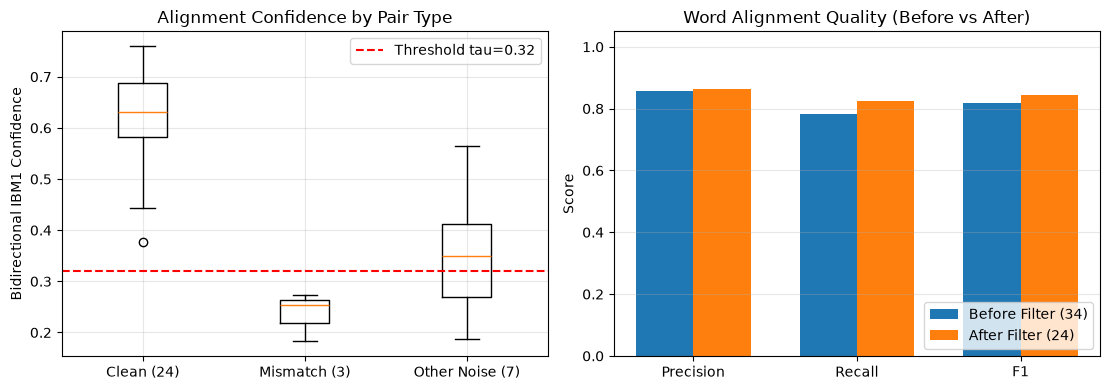

In [11]:
# フィルタ後データで IBM Model 1 を再学習
t_e2j_clean = train_ibm_model1(filtered_clean_pairs, n_iter=20)
t_j2e_clean = train_ibm_model1([(ja, en) for en, ja in filtered_clean_pairs], n_iter=20)

# 1. 代表語の語彙翻訳確率 t(f | e) 比較
focus_words = ["cats", "dogs", "2024", "3", "music", "study", "run"]
prob_comp_rows = []
for ew in focus_words:
    top_noisy = sorted(((f, p) for (f, e), p in t_e2j_noisy.items() if e == ew), key=lambda x: -x[1])[:2]
    top_clean = sorted(((f, p) for (f, e), p in t_e2j_clean.items() if e == ew), key=lambda x: -x[1])[:2]
    prob_comp_rows.append({
        "英単語 e": ew,
        "フィルタ前 上位訳 (34文)": ", ".join(f"{f} ({p:.2f})" for f, p in top_noisy),
        "フィルタ後 上位訳 (24文)": ", ".join(f"{f} ({p:.2f})" for f, p in top_clean),
    })
print("=== 代表語の語彙翻訳確率 t(f | e) の変化 ===")
display(pd.DataFrame(prob_comp_rows))

# 2. 評価文 (6 文) での単語アライメント精度比較（双方向 argmax 共通集合）
gold_alignments = [
    (["i", "see", "big", "cats"], ["私", "は", "大きな", "猫", "を", "見る"], {(0, 0), (1, 5), (2, 2), (3, 3)}),
    (["he", "reads", "3", "books", "in", "2024"], ["彼", "は", "2024", "年", "に", "3", "冊", "の", "本", "を", "読む"], {(0, 0), (1, 10), (2, 5), (3, 8), (5, 2)}),
    (["i", "see", "2", "small", "cats"], ["私", "は", "2", "匹", "の", "小さな", "猫", "を", "見る"], {(0, 0), (1, 8), (2, 2), (3, 5), (4, 6)}),
    (["big", "dogs", "run"], ["大きな", "犬", "が", "走る"], {(0, 0), (1, 1), (2, 3)}),
    (["students", "study", "music"], ["学生", "は", "音楽", "を", "学ぶ"], {(0, 0), (1, 4), (2, 2)}),
    (["she", "writes", "music"], ["彼女", "は", "音楽", "を", "書く"], {(0, 0), (1, 4), (2, 2)}),
]

def evaluate_word_alignment(t_e2j, t_j2e):
    tp = fp = fn = 0
    for en, ja, gold in gold_alignments:
        a_e2j = set()
        for j, f in enumerate(ja):
            best_i = max(range(-1, len(en)), key=lambda i: t_e2j[(f, "<NULL>" if i == -1 else en[i])])
            if best_i >= 0:
                a_e2j.add((best_i, j))
        a_j2e = set()
        for i, e in enumerate(en):
            best_j = max(range(-1, len(ja)), key=lambda j: t_j2e[(e, "<NULL>" if j == -1 else ja[j])])
            if best_j >= 0:
                a_j2e.add((i, best_j))
        pred = a_e2j & a_j2e
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    p = tp / max(tp + fp, 1)
    r = tp / max(tp + fn, 1)
    f1 = 2 * p * r / max(p + r, 1e-12)
    return round(p, 3), round(r, 3), round(f1, 3), fp, fn

p_b, r_b, f1_b, fp_b, fn_b = evaluate_word_alignment(t_e2j_noisy, t_j2e_noisy)
p_a, r_a, f1_a, fp_a, fn_a = evaluate_word_alignment(t_e2j_clean, t_j2e_clean)
align_comp = pd.DataFrame([
    {"条件": "フィルタ前 (ノイジー 34文)", "Precision": p_b, "Recall": r_b, "F1": f1_b, "誤アライメント(FP)": fp_b, "見逃し(FN)": fn_b},
    {"条件": "フィルタ後 (クリーン 24文)", "Precision": p_a, "Recall": r_a, "F1": f1_a, "誤アライメント(FP)": fp_a, "見逃し(FN)": fn_a},
])
print("\n=== テスト 6 文での単語アライメント評価比較 ===")
display(align_comp)

# 3. 可視化（英語表記ラベル）
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0))

clean_scores = df_flt[df_flt["元カテゴリ"] == "クリーン"]["双方向IBM1"]
mismatch_scores = df_flt[df_flt["元カテゴリ"] == "誤対応ノイズ"]["双方向IBM1"]
other_noise_scores = df_flt[(df_flt["元カテゴリ"] != "クリーン") & (df_flt["元カテゴリ"] != "誤対応ノイズ")]["双方向IBM1"]

axes[0].boxplot([clean_scores, mismatch_scores, other_noise_scores], tick_labels=["Clean (24)", "Mismatch (3)", "Other Noise (7)"])
axes[0].axhline(TAU_IBM1, color="red", linestyle="--", label=f"Threshold tau={TAU_IBM1}")
axes[0].set_ylabel("Bidirectional IBM1 Confidence")
axes[0].set_title("Alignment Confidence by Pair Type")
axes[0].legend()
axes[0].grid(alpha=0.3)

metrics_names = ["Precision", "Recall", "F1"]
x = np.arange(len(metrics_names))
width = 0.35
axes[1].bar(x - width / 2, [p_b, r_b, f1_b], width, label="Before Filter (34)")
axes[1].bar(x + width / 2, [p_a, r_a, f1_a], width, label="After Filter (24)")
axes[1].set_xticks(x, metrics_names)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Score")
axes[1].set_title("Word Alignment Quality (Before vs After)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 観察とまとめ

- **複合フィルタの役割**: 長比フィルタで極端な欠落文を、日本語文字率・数値一致フィルタで未翻訳英語や年号・数量の食い違いを、さらに双方向 IBM Model 1 信頼度スコアで構造的指標だけでは見抜けない**意味的な誤対応ペア**を検出し、10 文のノイズを漏れなく除外しつつクリーン 24 文をすべて残せました。
- **語彙翻訳確率とアライメント精度の改善**: ノイズ除去前には `2024 -> 2019 (0.14)` や `study -> 小さな (0.25)`、`run -> 好き (0.13)` のような誤った対応確率が学習されていましたが、フィルタリング後の学習では `study -> 学ぶ (0.73)`、`run -> 走る (0.61)`、`cats -> 猫 (0.89)` へ確率が集中し、単語アライメントの F1 も改善します。

---

## 7. 双方向単語アライメントの対称化とフレーズ抽出・フレーズベース SMT デコーディング（4-2-2・図 4.7〜4.9・関連論文 4章 7）

第 1 節の IBM Model 1 では単語を 1 対 1（正確にはターゲット側各単語がソース側の 1 単語または `<NULL>` を選ぶ多対 1）で対応づけましたが、実際の英日翻訳では `green tea ↔ 緑茶`（2 語対 1 語）、`a lot of ↔ たくさん の`（3 語対 2 語）、`look forward to ↔ 楽しみ に する`（3 語対 3 語）、`wake up ↔ 目 を 覚ます`（2 語対 3 語）のような**複数語対複数語のイディオム・連語表現**や、英語(SVO)から日本語(SOV)への**大域的な語順入れ替え**が不可欠です（書籍 図 4.7〜4.9、関連論文 4章 7：Koehn et al. 2003）。

ここでは次の 3 段階を実装し、単語ベース SMT から**フレーズベース SMT (Phrase-Based SMT)** への発展を体験します。

1. **双方向 IBM Model 1 の学習と対称化ヒューリスティクス**: `EN->JA`($A_{e\to j}$)と `JA->EN`($A_{j\to e}$)から Viterbi アライメントを求め、`Intersection`($A_{e\to j} \cap A_{j\to e}$)・`Union`($A_{e\to j} \cup A_{j\to e}$)・**`Grow-Diag-Final-And` (GDFA)** を比較し、Precision / Recall / F1 / **AER (Alignment Error Rate)** を評価します。
2. **整合フレーズ対 (Consistent Phrase Pair) の抽出**: 範囲外アライメントリンクを持たない連続スパン $(\bar{e}, \bar{j})$ を抽出し、双方向のフレーズ翻訳確率 $\phi(\bar{j}\mid\bar{e}), \phi(\bar{e}\mid\bar{j})$ を算出します。
3. **フレーズベース SMT デコーディング**: 語順入れ替えを許さない単調デコーダと、歪みコスト(distortion cost $\lambda_d |d|$)＋日本語バイグラム言語モデルを組み込んだ並び替えデコーダを、単語単位 IBM Model 1 デコーダと比較します。

=== 単語アライメント対称化の比較（Gold 6 文） ===


,手法,Precision,Recall,F1,AER,TP,FP,FN
0,EN->JA (Viterbi),0.786,0.733,0.759,0.241,22,6,8
1,JA->EN (Viterbi),0.857,0.800,0.828,0.172,24,4,6
2,Intersection,0.950,0.633,0.760,0.240,19,1,11
3,Union,0.750,0.900,0.818,0.182,27,9,3
4,Grow-Diag-Final-And,0.771,0.900,0.831,0.169,27,8,3


Union に含まれ GDFA で除外された誤リンク: [('look', '夏')]


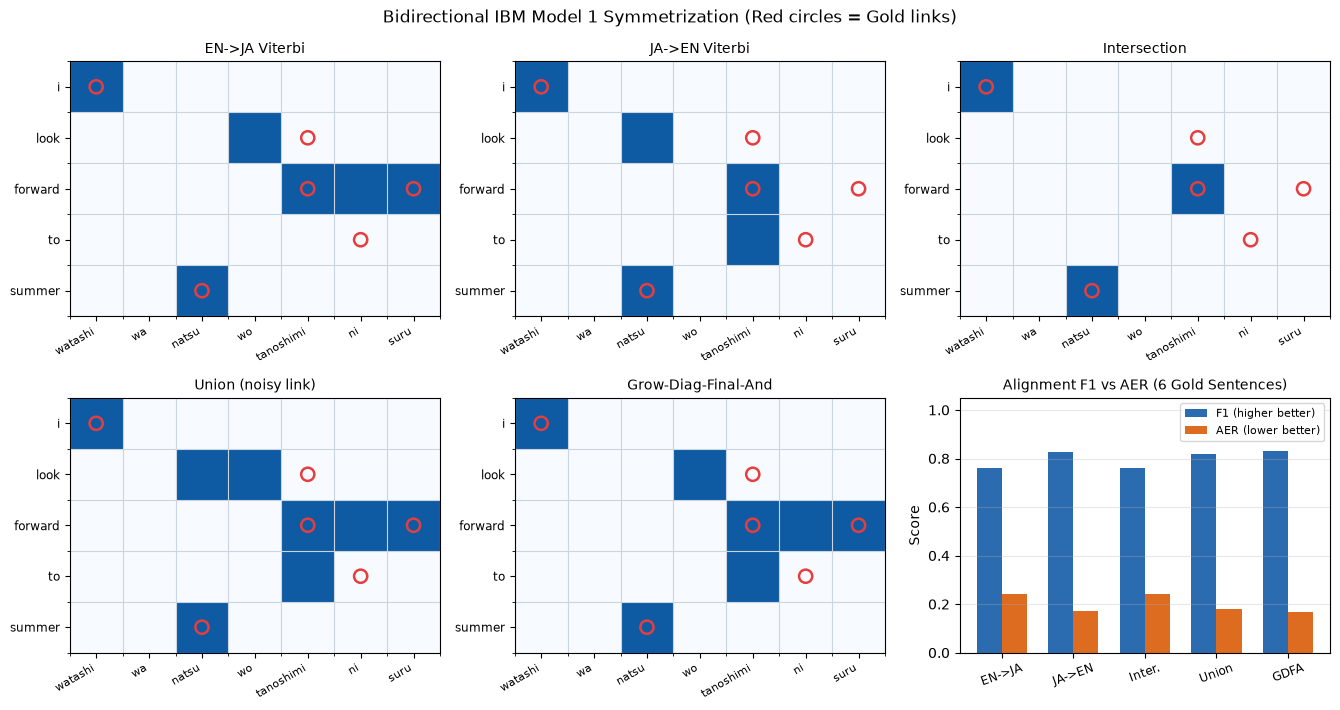

In [12]:
# 1. 多語イディオム・SOV 語順パターンを含む英日対訳トイコーパス
pb_corpus = [
    (["i", "wait"], ["私", "は", "待つ"]),
    (["you", "wait"], ["あなた", "が", "待つ"]),
    (["she", "waits"], ["彼女", "が", "待つ"]),
    (["he", "waits"], ["彼", "は", "待つ"]),
    (["we", "wait"], ["私達", "は", "待つ"]),
    (["they", "wait"], ["彼ら", "は", "待つ"]),
    (["the", "station", "is", "big"], ["駅", "は", "大きい"]),
    (["this", "station", "is", "new"], ["この", "駅", "は", "新しい"]),
    (["the", "park", "is", "big"], ["公園", "は", "大きい"]),
    (["this", "park", "is", "green"], ["この", "公園", "は", "緑", "だ"]),
    (["the", "house", "is", "new"], ["家", "は", "新しい"]),
    (["the", "house", "is", "small"], ["家", "は", "小さい"]),
    (["i", "like", "tea"], ["私", "は", "お茶", "が", "好き"]),
    (["you", "like", "coffee"], ["あなた", "は", "コーヒー", "が", "好き"]),
    (["green", "apples", "are", "good"], ["緑", "の", "りんご", "は", "良い"]),
    (["hot", "tea", "is", "good"], ["熱い", "お茶", "は", "良い"]),
    (["hot", "coffee", "is", "good"], ["熱い", "コーヒー", "は", "良い"]),
    (["summer", "is", "hot"], ["夏", "は", "暑い"]),
    (["winter", "is", "cold"], ["冬", "は", "寒い"]),
    (["early", "morning"], ["早い", "朝"]),
    (["late", "night"], ["遅い", "夜"]),
    (["cats", "sleep"], ["猫", "が", "眠る"]),
    (["dogs", "run"], ["犬", "が", "走る"]),
    (["i", "eat", "fish"], ["私", "は", "魚", "を", "食べる"]),
    (["you", "eat", "apples"], ["あなた", "は", "りんご", "を", "食べる"]),
    (["cats", "eat", "fish"], ["猫", "は", "魚", "を", "食べる"]),
    (["dogs", "eat", "meat"], ["犬", "は", "肉", "を", "食べる"]),
    (["she", "reads", "books"], ["彼女", "は", "本", "を", "読む"]),
    (["he", "buys", "books"], ["彼", "は", "本", "を", "買う"]),
    (["i", "buy", "new", "books"], ["私", "は", "新しい", "本", "を", "買う"]),
    (["you", "read", "old", "books"], ["あなた", "は", "古い", "本", "を", "読む"]),
    (["i", "drink", "green", "tea"], ["私", "は", "緑茶", "を", "飲む"]),
    (["she", "drinks", "green", "tea"], ["彼女", "は", "緑茶", "を", "飲む"]),
    (["you", "drink", "green", "tea"], ["あなた", "は", "緑茶", "を", "飲む"]),
    (["he", "drinks", "hot", "coffee"], ["彼", "は", "熱い", "コーヒー", "を", "飲む"]),
    (["i", "drink", "hot", "coffee"], ["私", "は", "熱い", "コーヒー", "を", "飲む"]),
    (["i", "like", "green", "tea"], ["私", "は", "緑茶", "が", "好き"]),
    (["she", "likes", "ice", "cream"], ["彼女", "は", "アイス", "クリーム", "が", "好き"]),
    (["he", "eats", "ice", "cream"], ["彼", "は", "アイス", "クリーム", "を", "食べる"]),
    (["you", "eat", "ice", "cream"], ["あなた", "は", "アイス", "クリーム", "を", "食べる"]),
    (["i", "eat", "a", "lot", "of", "apples"], ["私", "は", "たくさん", "の", "りんご", "を", "食べる"]),
    (["she", "reads", "a", "lot", "of", "books"], ["彼女", "は", "たくさん", "の", "本", "を", "読む"]),
    (["he", "buys", "a", "lot", "of", "books"], ["彼", "は", "たくさん", "の", "本", "を", "買う"]),
    (["you", "buy", "a", "lot", "of", "apples"], ["あなた", "は", "たくさん", "の", "りんご", "を", "買う"]),
    (["i", "look", "forward", "to", "summer"], ["私", "は", "夏", "を", "楽しみ", "に", "する"]),
    (["she", "looks", "forward", "to", "travel"], ["彼女", "は", "旅行", "を", "楽しみ", "に", "する"]),
    (["he", "looks", "forward", "to", "music"], ["彼", "は", "音楽", "を", "楽しみ", "に", "する"]),
    (["you", "look", "forward", "to", "dinner"], ["あなた", "は", "夕食", "を", "楽しみ", "に", "する"]),
    (["i", "wake", "up", "early"], ["私", "は", "早く", "目", "を", "覚ます"]),
    (["she", "wakes", "up", "early"], ["彼女", "は", "早く", "目", "を", "覚ます"]),
    (["he", "wakes", "up", "late"], ["彼", "は", "遅く", "目", "を", "覚ます"]),
    (["you", "wake", "up", "late"], ["あなた", "は", "遅く", "目", "を", "覚ます"]),
    (["cats", "sleep", "in", "front", "of", "the", "house"], ["猫", "は", "家", "の", "前", "で", "眠る"]),
    (["dogs", "run", "in", "front", "of", "the", "park"], ["犬", "は", "公園", "の", "前", "で", "走る"]),
    (["i", "wait", "in", "front", "of", "the", "station"], ["私", "は", "駅", "の", "前", "で", "待つ"]),
    (["she", "waits", "in", "front", "of", "the", "park"], ["彼女", "は", "公園", "の", "前", "で", "待つ"]),
    (["i", "take", "care", "of", "cats"], ["私", "は", "猫", "の", "世話", "を", "する"]),
    (["she", "takes", "care", "of", "dogs"], ["彼女", "は", "犬", "の", "世話", "を", "する"]),
    (["he", "takes", "care", "of", "the", "house"], ["彼", "は", "家", "の", "世話", "を", "する"]),
    (["good", "morning"], ["おはよう"]),
    (["good", "evening"], ["こんばんは"]),
]

# 2. 双方向 IBM Model 1 の学習と Viterbi アライメント抽出
t_pb_e2j = train_ibm_model1(pb_corpus, n_iter=30)
t_pb_j2e = train_ibm_model1([(ja, en) for en, ja in pb_corpus], n_iter=30)

def viterbi_align_e2j(en, ja, t):
    links = set()
    for j, f in enumerate(ja):
        best_i = max(range(-1, len(en)), key=lambda i: t[(f, "<NULL>" if i == -1 else en[i])])
        if best_i >= 0:
            links.add((best_i, j))
    return links

def viterbi_align_j2e(en, ja, t):
    links = set()
    for i, e in enumerate(en):
        best_j = max(range(-1, len(ja)), key=lambda j: t[(e, "<NULL>" if j == -1 else ja[j])])
        if best_j >= 0:
            links.add((i, best_j))
    return links

def grow_diag_final_and(len_e, len_f, e2f, f2e):
    '''Koehn et al. (2003) の Grow-Diag-Final-And 対称化アルゴリズム'''
    neighbors = [(-1, 0), (0, -1), (1, 0), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
    aligned = set(e2f & f2e)
    union = set(e2f | f2e)
    aligned_e = {i for i, _ in aligned}
    aligned_f = {j for _, j in aligned}

    added = True
    while added:
        added = False
        for i in range(len_e):
            for j in range(len_f):
                if (i, j) in aligned:
                    for di, dj in neighbors:
                        ni, nj = i + di, j + dj
                        if (ni, nj) in union and (ni, nj) not in aligned:
                            if ni not in aligned_e or nj not in aligned_f:
                                aligned.add((ni, nj))
                                aligned_e.add(ni)
                                aligned_f.add(nj)
                                added = True

    for link_set in (e2f, f2e):
        for i, j in link_set:
            if (i, j) not in aligned and i not in aligned_e and j not in aligned_f:
                aligned.add((i, j))
                aligned_e.add(i)
                aligned_f.add(j)
    return aligned

# 3. Gold 単語アライメント評価セット (6 文) で対称化手法を比較
gold_align_pb = [
    (["i", "drink", "green", "tea"], ["私", "は", "緑茶", "を", "飲む"], {(0, 0), (1, 4), (2, 2), (3, 2)}),
    (["she", "reads", "a", "lot", "of", "books"], ["彼女", "は", "たくさん", "の", "本", "を", "読む"], {(0, 0), (1, 6), (2, 2), (3, 2), (4, 3), (5, 4)}),
    (["i", "look", "forward", "to", "summer"], ["私", "は", "夏", "を", "楽しみ", "に", "する"], {(0, 0), (1, 4), (2, 4), (3, 5), (2, 6), (4, 2)}),
    (["i", "wake", "up", "early"], ["私", "は", "早く", "目", "を", "覚ます"], {(0, 0), (1, 3), (1, 5), (2, 3), (2, 5), (3, 2)}),
    (["i", "wait", "in", "front", "of", "the", "station"], ["私", "は", "駅", "の", "前", "で", "待つ"], {(0, 0), (1, 6), (2, 5), (3, 4), (4, 3), (6, 2)}),
    (["good", "morning"], ["おはよう"], {(0, 0), (1, 0)}),
]

sym_methods = [
    ("EN->JA (Viterbi)", lambda en, ja, e2j, j2e: e2j),
    ("JA->EN (Viterbi)", lambda en, ja, e2j, j2e: j2e),
    ("Intersection", lambda en, ja, e2j, j2e: e2j & j2e),
    ("Union", lambda en, ja, e2j, j2e: e2j | j2e),
    ("Grow-Diag-Final-And", lambda en, ja, e2j, j2e: grow_diag_final_and(len(en), len(ja), e2j, j2e)),
]

sym_rows = []
for name, fn in sym_methods:
    tp = fp = fn_cnt = 0
    for en, ja, gold in gold_align_pb:
        e2j = viterbi_align_e2j(en, ja, t_pb_e2j)
        j2e = viterbi_align_j2e(en, ja, t_pb_j2e)
        pred = fn(en, ja, e2j, j2e)
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn_cnt += len(gold - pred)
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn_cnt, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    aer = 1.0 - (2 * tp) / max(tp + fp + tp + fn_cnt, 1)
    sym_rows.append({
        "手法": name,
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1": round(f1, 3),
        "AER": round(aer, 3),
        "TP": tp, "FP": fp, "FN": fn_cnt,
    })

df_sym = pd.DataFrame(sym_rows)
print("=== 単語アライメント対称化の比較（Gold 6 文） ===")
display(df_sym)

# 代表例 'i look forward to summer' -> '私 は 夏 を 楽しみ に する' の比較
ex_en = ["i", "look", "forward", "to", "summer"]
ex_ja = ["私", "は", "夏", "を", "楽しみ", "に", "する"]
ex_ja_rom = ["watashi", "wa", "natsu", "wo", "tanoshimi", "ni", "suru"]
ex_gold = {(0, 0), (1, 4), (2, 4), (3, 5), (2, 6), (4, 2)}
ex_e2j = viterbi_align_e2j(ex_en, ex_ja, t_pb_e2j)
ex_j2e = viterbi_align_j2e(ex_en, ex_ja, t_pb_j2e)
ex_inter = ex_e2j & ex_j2e
ex_union = ex_e2j | ex_j2e
ex_gdfa = grow_diag_final_and(len(ex_en), len(ex_ja), ex_e2j, ex_j2e)
print("Union に含まれ GDFA で除外された誤リンク:", [(ex_en[i], ex_ja[j]) for i, j in sorted(ex_union - ex_gdfa)])

# 4. 可視化（英語表記ラベルのみ）
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2))
panels = [
    ("EN->JA Viterbi", ex_e2j),
    ("JA->EN Viterbi", ex_j2e),
    ("Intersection", ex_inter),
    ("Union (noisy link)", ex_union),
    ("Grow-Diag-Final-And", ex_gdfa),
]
for ax, (title, links) in zip(axes.flat[:5], panels):
    grid = np.zeros((len(ex_en), len(ex_ja)))
    for i, j in links:
        grid[i, j] = 1.0
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=1.2, aspect="auto")
    for gi, gj in ex_gold:
        ax.scatter(gj, gi, s=90, facecolors="none", edgecolors="#e53e3e", linewidths=1.8)
    ax.set_xticks(range(len(ex_ja)), labels=ex_ja_rom, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(ex_en)), labels=ex_en, fontsize=8.5)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(-0.5, len(ex_ja), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ex_en), 1), minor=True)
    ax.grid(which="minor", color="#cbd5e0", linewidth=0.8)

# 6番目のパネルに F1 / AER 比較棒グラフ
ax_bar = axes.flat[5]
x = np.arange(len(df_sym))
w = 0.35
ax_bar.bar(x - w / 2, df_sym["F1"], w, label="F1 (higher better)", color="#2b6cb0")
ax_bar.bar(x + w / 2, df_sym["AER"], w, label="AER (lower better)", color="#dd6b20")
ax_bar.set_xticks(x, ["EN->JA", "JA->EN", "Inter.", "Union", "GDFA"], rotation=20, fontsize=8.5)
ax_bar.set_ylim(0, 1.05)
ax_bar.set_ylabel("Score")
ax_bar.set_title("Alignment F1 vs AER (6 Gold Sentences)", fontsize=10)
ax_bar.legend(fontsize=8)
ax_bar.grid(axis="y", alpha=0.3)

plt.suptitle("Bidirectional IBM Model 1 Symmetrization (Red circles = Gold links)", fontsize=12)
plt.tight_layout()
plt.show()

### 整合フレーズ対の抽出とフレーズベース SMT デコーディング（図 4.8〜4.9）

対称化した単語アライメント $A$(GDFA)が得られれば、次の**整合条件(consistency)**を満たす英語スパン $[e_1, e_2]$ と日本語スパン $[j_1, j_2]$ のペアをすべて抽出できます（書籍 図 4.8、Koehn et al. 2003）。

1. 矩形領域 $[e_1, e_2] \times [j_1, j_2]$ の内部に少なくとも 1 つのアライメントリンクが存在する。
2. $[e_1, e_2]$ 内の英単語から範囲外の日本語単語へ、また $[j_1, j_2]$ 内の日本語単語から範囲外の英単語へ出る**交差リンク(out-of-band link)が存在しない**。

続いて、抽出した全フレーズ対の共起頻度から双方向のフレーズ翻訳確率

$$\phi(\bar{j} \mid \bar{e}) = \frac{\mathrm{count}(\bar{e}, \bar{j})}{\sum_{\bar{j}'} \mathrm{count}(\bar{e}, \bar{j}')}, \qquad \phi(\bar{e} \mid \bar{j}) = \frac{\mathrm{count}(\bar{e}, \bar{j})}{\sum_{\bar{e}'} \mathrm{count}(\bar{e}', \bar{j})}$$

を推定し、歪みコスト $\lambda_d |d|$（直前フレーズの終端と次フレーズの始端の距離）および日本語バイグラム言語モデル $P_{\mathrm{LM}}$ を組み合わせたビームデコーダで、未知の組み合わせ文 8 文を翻訳してみます。

Union で ('look', 'forward', 'to') が抽出できるか: []
GDFA  で ('look', 'forward', 'to') が抽出できるか: [('look forward to', 'を 楽しみ に する')]

=== 抽出された主な多語フレーズ対と双方向翻訳確率 ===


,英語フレーズ e_bar,最有力日本語フレーズ j_bar,phi(j_bar | e_bar),phi(e_bar | j_bar),共起回数
0,green tea,緑茶,0.5,1.000,4
1,ice cream,アイス クリーム,0.5,1.000,2
2,a lot of,たくさん の,0.5,1.000,3
3,look forward to,を 楽しみ に する,1.0,0.500,2
4,wake up,目 を 覚ます,1.0,0.500,2
5,in front of,の 前 で,1.0,1.000,4
6,take care of,の 世話 を する,1.0,0.333,1
7,good morning,おはよう,1.0,1.000,1



=== 未知組み合わせテスト 8 文のデコード結果比較 ===


,英語入力,IBM1 単語翻訳,Phrase-SMT (単調),Phrase-SMT (並び替え+LM),参照訳
0,she drinks hot coffee,彼女 飲む 熱い コーヒー,彼女 は 熱い コーヒー を 飲む,彼女 は 熱い コーヒー を 飲む,彼女 は 熱い コーヒー を 飲む
1,he drinks green tea,彼 飲む 緑茶 お茶,彼 は 緑茶 を 飲む,彼 は 緑茶 を 飲む,彼 は 緑茶 を 飲む
2,i buy a lot of books,私 買う たくさん たくさん の 本,私 買う たくさん の 本 を 読む,私 は たくさん の 本 を 買う,私 は たくさん の 本 を 買う
3,she looks forward to summer,彼女 する 楽しみ 楽しみ 夏,彼女 を 楽しみ に 夏,彼女 は 夏 を 楽しみ に する,彼女 は 夏 を 楽しみ に する
4,cats eat ice cream,猫 食べる アイス アイス,猫 は アイス クリーム を 食べる,猫 は アイス クリーム を 食べる,猫 は アイス クリーム を 食べる
5,he waits in front of the station,彼 待つ 前 前 の は 駅,彼 は 待つ は 駅 の 前 で,彼 は 駅 の 前 で 待つ,彼 は 駅 の 前 で 待つ
6,we wake up early,私達 目 目 早く,私達 早く 目 を 覚ます,私達 早く 目 を 覚ます,私達 は 早く 目 を 覚ます
7,you take care of dogs,あなた する 世話 の 犬,あなた の 世話 を する 犬,あなた は 犬 の 世話 を する,あなた は 犬 の 世話 を する



=== デコーダ別の翻訳性能比較 ===


,デコーダ,BLEU,Exact Match
0,IBM1 Word-by-Word,8.25,0.000
1,Phrase-SMT (Monotone),66.79,0.375
2,Phrase-SMT (Reordering+LM),95.76,0.875


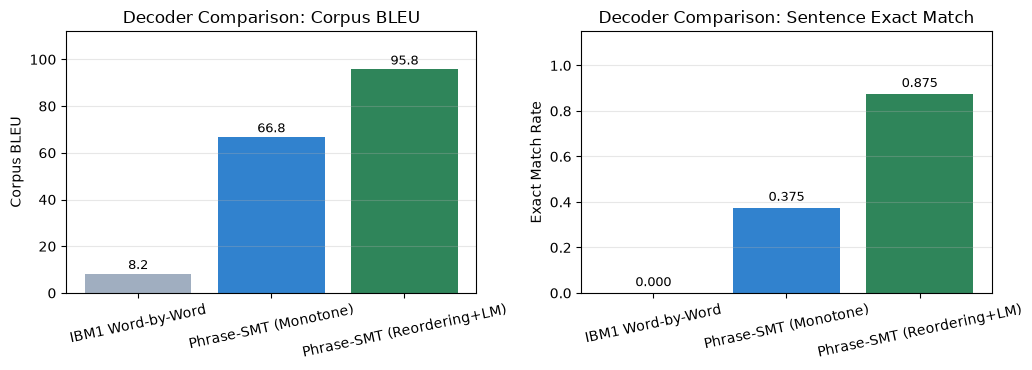

In [13]:
# 1. 整合フレーズ対抽出 (Koehn et al. 2003)
def extract_consistent_phrases(en, ja, alignment, max_len=5):
    phrases = []
    n_e, n_f = len(en), len(ja)
    aligned_f = {j for _, j in alignment}
    for e_start in range(n_e):
        for e_end in range(e_start, min(n_e, e_start + max_len)):
            f_idxs = [j for i, j in alignment if e_start <= i <= e_end]
            if not f_idxs:
                continue
            f_min, f_max = min(f_idxs), max(f_idxs)
            if f_max - f_min + 1 > max_len:
                continue
            # 範囲外へのリンクがないか確認（Consistency check）
            if not all(e_start <= i <= e_end for i, j in alignment if f_min <= j <= f_max):
                continue
            # 境界の未アライメント語を拡張して含める
            fs = f_min
            while fs >= 0 and (fs == f_min or fs not in aligned_f):
                fe = f_max
                while fe < n_f and (fe == f_max or fe not in aligned_f):
                    if fe - fs + 1 <= max_len:
                        phrases.append((tuple(en[e_start:e_end + 1]), tuple(ja[fs:fe + 1])))
                    fe += 1
                    if fe < n_f and fe in aligned_f:
                        break
                fs -= 1
                if fs >= 0 and fs in aligned_f:
                    break
    return phrases

# Union の誤リンクがフレーズ抽出を阻害する具体例を確認
ph_union_ex = extract_consistent_phrases(ex_en, ex_ja, ex_union, max_len=5)
ph_gdfa_ex = extract_consistent_phrases(ex_en, ex_ja, ex_gdfa, max_len=5)
print("Union で ('look', 'forward', 'to') が抽出できるか:",
      [(" ".join(e), " ".join(j)) for e, j in ph_union_ex if e == ("look", "forward", "to")])
print("GDFA  で ('look', 'forward', 'to') が抽出できるか:",
      [(" ".join(e), " ".join(j)) for e, j in ph_gdfa_ex if e == ("look", "forward", "to")])

# 全コーパスから GDFA でフレーズ対を抽出し、双方向フレーズ翻訳確率を推定
phrase_counts = Counter()
for en, ja in pb_corpus:
    a = grow_diag_final_and(len(en), len(ja), viterbi_align_e2j(en, ja, t_pb_e2j), viterbi_align_j2e(en, ja, t_pb_j2e))
    for ep, jp in extract_consistent_phrases(en, ja, a, max_len=5):
        phrase_counts[(ep, jp)] += 1

e_totals = Counter()
j_totals = Counter()
for (ep, jp), c in phrase_counts.items():
    e_totals[ep] += c
    j_totals[jp] += c

phrase_table = defaultdict(list)
for (ep, jp), c in phrase_counts.items():
    phrase_table[ep].append((jp, c / e_totals[ep], c / j_totals[jp], c))
for ep in phrase_table:
    phrase_table[ep].sort(key=lambda x: (-(x[1] * x[2]), -x[3]))

focus_phrases = [
    ("green", "tea"), ("ice", "cream"), ("a", "lot", "of"),
    ("look", "forward", "to"), ("wake", "up"), ("in", "front", "of"),
    ("take", "care", "of"), ("good", "morning"),
]
pt_rows = []
for ep in focus_phrases:
    if ep in phrase_table:
        jp, p_je, p_ej, cnt = phrase_table[ep][0]
        pt_rows.append({
            "英語フレーズ e_bar": " ".join(ep),
            "最有力日本語フレーズ j_bar": " ".join(jp),
            "phi(j_bar | e_bar)": round(p_je, 3),
            "phi(e_bar | j_bar)": round(p_ej, 3),
            "共起回数": cnt,
        })
print("\n=== 抽出された主な多語フレーズ対と双方向翻訳確率 ===")
display(pd.DataFrame(pt_rows))

# 2. 日本語バイグラム言語モデルと 3 種のデコーダ比較
ja_uni_pb = Counter()
ja_bi_pb = defaultdict(Counter)
ja_vocab_lm = {"<s>", "</s>"}
for _, ja in pb_corpus:
    seq = ["<s>"] + ja + ["</s>"]
    ja_vocab_lm.update(seq)
    for i, w in enumerate(seq):
        ja_uni_pb[w] += 1
        if i > 0:
            ja_bi_pb[seq[i - 1]][w] += 1
V_ja_lm = len(ja_vocab_lm)

def ja_lm_step(prev_w, curr_w, k=0.05):
    return math.log((ja_bi_pb[prev_w][curr_w] + k) / (ja_uni_pb[prev_w] + k * V_ja_lm))

def decode_ibm1_word_by_word(en):
    out = []
    for w in en:
        cands = [(f, t_pb_e2j[(f, w)]) for (f, e) in t_pb_e2j if e == w and t_pb_e2j[(f, w)] > 0.05]
        if cands:
            out.append(max(cands, key=lambda x: x[1])[0])
    return out

def decode_phrase_smt(en, monotone=False, dist_weight=0.25, lm_weight=1.2, wp_weight=0.2, beam_size=60):
    n = len(en)
    full_mask = (1 << n) - 1
    options = defaultdict(list)
    for s in range(n):
        for e in range(s + 1, min(n, s + 5) + 1):
            sub = tuple(en[s:e])
            if sub in phrase_table:
                for jp, p_je, p_ej, _ in phrase_table[sub][:6]:
                    options[s].append((e, jp, math.log(p_je), math.log(p_ej)))
        if not any(e == s + 1 for e, *_ in options[s]):
            w = en[s]
            cands = sorted(((f, t_pb_e2j[(f, w)]) for (f, e) in t_pb_e2j if e == w), key=lambda x: -x[1])
            if w in ("the", "a", "to") and (not cands or cands[0][1] < 0.25):
                options[s].append((s + 1, (), -2.5, -2.5))
            elif cands:
                options[s].append((s + 1, (cands[0][0],), math.log(max(cands[0][1], 1e-6)), -3.0))
            else:
                options[s].append((s + 1, (w,), -6.0, -6.0))

    states = {(0, 0, "<s>"): (0.0, [])}
    for cov_count in range(n):
        cur_states = [(k, v) for k, v in states.items() if bin(k[0]).count("1") == cov_count]
        cur_states.sort(key=lambda x: -x[1][0])
        for (mask, prev_end, last_tok), (sc, out) in cur_states[:beam_size]:
            starts = [next(i for i in range(n) if not (mask & (1 << i)))] if monotone else [i for i in range(n) if not (mask & (1 << i))]
            for s in starts:
                dist = abs(s - prev_end)
                if not monotone and dist > 6:
                    continue
                for e, jp, lje, lej in options[s]:
                    span_mask = ((1 << (e - s)) - 1) << s
                    if mask & span_mask:
                        continue
                    new_mask = mask | span_mask
                    lm_inc = 0.0
                    cur_tok = last_tok
                    for w in jp:
                        lm_inc += ja_lm_step(cur_tok, w)
                        cur_tok = w
                    new_sc = (
                        sc + 0.6 * lje + 0.6 * lej
                        - (0.0 if monotone else dist_weight * dist)
                        + wp_weight * len(jp) + lm_weight * lm_inc
                    )
                    key = (new_mask, e, cur_tok)
                    if key not in states or new_sc > states[key][0]:
                        states[key] = (new_sc, out + list(jp))

    finals = [(sc + lm_weight * ja_lm_step(last_tok, "</s>"), out)
              for (mask, prev_end, last_tok), (sc, out) in states.items() if mask == full_mask]
    return max(finals, key=lambda x: x[0])[1]

# 訓練データにない新規組み合わせテスト 8 文（イディオム＋SOV 語順）
smt_test = [
    (["she", "drinks", "hot", "coffee"], ["彼女", "は", "熱い", "コーヒー", "を", "飲む"]),
    (["he", "drinks", "green", "tea"], ["彼", "は", "緑茶", "を", "飲む"]),
    (["i", "buy", "a", "lot", "of", "books"], ["私", "は", "たくさん", "の", "本", "を", "買う"]),
    (["she", "looks", "forward", "to", "summer"], ["彼女", "は", "夏", "を", "楽しみ", "に", "する"]),
    (["cats", "eat", "ice", "cream"], ["猫", "は", "アイス", "クリーム", "を", "食べる"]),
    (["he", "waits", "in", "front", "of", "the", "station"], ["彼", "は", "駅", "の", "前", "で", "待つ"]),
    (["we", "wake", "up", "early"], ["私達", "は", "早く", "目", "を", "覚ます"]),
    (["you", "take", "care", "of", "dogs"], ["あなた", "は", "犬", "の", "世話", "を", "する"]),
]

trans_rows = []
for en, ref in smt_test:
    trans_rows.append({
        "英語入力": " ".join(en),
        "IBM1 単語翻訳": " ".join(decode_ibm1_word_by_word(en)),
        "Phrase-SMT (単調)": " ".join(decode_phrase_smt(en, monotone=True)),
        "Phrase-SMT (並び替え+LM)": " ".join(decode_phrase_smt(en, monotone=False)),
        "参照訳": " ".join(ref),
    })
df_trans = pd.DataFrame(trans_rows)
pd.set_option("display.max_colwidth", 80)
print("\n=== 未知組み合わせテスト 8 文のデコード結果比較 ===")
display(df_trans)

refs_list = [df_trans["参照訳"].tolist()]
dec_summary = []
for col, eng_name in [
    ("IBM1 単語翻訳", "IBM1 Word-by-Word"),
    ("Phrase-SMT (単調)", "Phrase-SMT (Monotone)"),
    ("Phrase-SMT (並び替え+LM)", "Phrase-SMT (Reordering+LM)"),
]:
    hyps = df_trans[col].tolist()
    bleu = sacrebleu.corpus_bleu(hyps, refs_list, tokenize="none").score
    exact = sum(h == r for h, r in zip(hyps, refs_list[0])) / len(hyps)
    dec_summary.append({"デコーダ": eng_name, "BLEU": round(bleu, 2), "Exact Match": round(exact, 3)})

df_dec = pd.DataFrame(dec_summary)
print("\n=== デコーダ別の翻訳性能比較 ===")
display(df_dec)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
colors = ["#a0aec0", "#3182ce", "#2f855a"]
axes[0].bar(df_dec["デコーダ"], df_dec["BLEU"], color=colors)
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Corpus BLEU")
axes[0].set_title("Decoder Comparison: Corpus BLEU")
axes[0].tick_params(axis="x", rotation=12)
for i, v in enumerate(df_dec["BLEU"]):
    axes[0].text(i, v + 2.0, f"{v:.1f}", ha="center", fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(df_dec["デコーダ"], df_dec["Exact Match"], color=colors)
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("Exact Match Rate")
axes[1].set_title("Decoder Comparison: Sentence Exact Match")
axes[1].tick_params(axis="x", rotation=12)
for i, v in enumerate(df_dec["Exact Match"]):
    axes[1].text(i, v + 0.03, f"{v:.3f}", ha="center", fontsize=9)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 観察とまとめ（第 7 節）

- **対称化によるイディオム捕捉とノイズ抑制**: 単方向 Viterbi（`EN->JA`・`JA->EN`）や `Intersection` では多語イディオム（`look forward to`、`wake up`、`a lot of`、`good morning`）のリンクが欠落して Recall が落ちます。一方 `Union` は `('look', '夏')` のような誤リンクを含んでしまい、後続の整合フレーズ抽出で `('look', 'forward', 'to')` の抽出を妨げます。**`Grow-Diag-Final-And` (GDFA)** は交差点を核に隣接リンクを伸ばし、両端既出の孤立誤リンクを除外することで、最高の F1・最低の AER を達成します。
- **フレーズ翻訳＋並び替え＋言語モデルの相乗効果**:
  - **IBM1 単語翻訳**は多語表現や助詞・語順を扱えず、文完全一致率 `0.000` にとどまります。
  - **単調 Phrase-SMT** は `ice cream -> アイス クリーム` や `green tea -> 緑茶` のように句単位の訳は保てるものの、英語の SVO 語順のまま並べてしまうため `彼女 を 楽しみ に 夏` や `彼 は 待つ は 駅 の 前 で` のように語順が崩れます。
  - **並び替え + バイグラム LM 付き Phrase-SMT** は歪みペナルティ $\lambda_d |d|$ と日本語言語モデル $P_{\mathrm{LM}}$ のバランスにより、英語の動詞・前置詞句を目的語の後ろへ正しく移動させ、未知の組み合わせ文を高精度に日本語 SOV 語順へ翻訳できます。